# Qwen3-VL backbone, step by step 🔭
### How an image becomes tokens inside a Qwen3 language model: dynamic resolution, 2-D RoPE, the 2×2 merger, DeepStack and interleaved M-RoPE

**Model:** Qwen3-VL (Qwen team, Alibaba, 2025). Dense sizes 2B / 4B / 8B / 32B and MoE 30B-A3B / 235B-A22B.
The vision side is a SigLIP-2 so400m ViT (patch 16, 27 blocks); the language side is Qwen3.

**What this notebook does:** it rebuilds the *backbone* of Qwen3-VL from scratch in plain PyTorch,
one mechanism at a time, and after every step **checks it numerically against the reference
implementation in 🤗 `transformers`** (`Qwen3VLModel`). A tiny random-weight configuration keeps
everything on a laptop CPU, with no downloads. The architecture is identical to the released
checkpoints; only the widths and depths are small. An optional cell at the end runs the same checks
on the real `Qwen/Qwen3-VL-2B-Instruct` weights.

| Step | Question it answers | Animation |
|---|---|---|
| 0 | What are the parts and the tensor shapes? | pipeline |
| 1 | How is the input resolution chosen? (`smart_resize`) | dynamic resolution |
| 2 | How are pixels cut into patches, and in what order? | 2×2 merge |
| 3 | How is a patch embedded? (Conv3d ≡ Linear) | |
| 4 | How does the ViT know where a patch is? (interpolated table + 2-D RoPE) | |
| 5 | How are several images attended in one batch? (packed `cu_seqlens`) | |
| 6 | How do 4 patches become 1 LLM token? (patch merger) | 2×2 merge |
| 7 | What is DeepStack? | DeepStack |
| 8 | Where do image tokens go in the prompt? | token stream |
| 9 | How are positions encoded in the LLM? (interleaved M-RoPE) | M-RoPE |
| 10 | The Qwen3 decoder layer, with DeepStack injection, end to end | |

> 🧩 **Reference code:** `transformers/models/qwen3_vl/modeling_qwen3_vl.py`, `transformers/vision_utils.py`,
> `transformers/models/qwen2_vl/image_processing_qwen2_vl.py` (Qwen3-VL reuses this processor).
> 🎞️ **Animations:** `hale_vlm.visualization.backbone_films`, rendered into `assets/backbone_films/`.

## Setup

The cell below makes the repo's `src/` importable (the notebook lives in `notebooks/backbones/vlm/`),
plus a sibling `HaleBlocks/src` checkout when present (as the repo's tests do),
quietens the library loggers and fixes the seeds. `FILMS` is where the animations are written.

In [1]:
import math, sys, warnings
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "hale_vlm").is_dir())
for src in (ROOT.parent / "HaleBlocks" / "src", ROOT / "src"):   # sibling HaleBlocks checkout, then this repo
    if src.is_dir():
        sys.path.insert(0, str(src))
FILMS = ROOT / "assets" / "backbone_films"

from loguru import logger
logger.remove(); logger.add(sys.stderr, level="WARNING")   # hide registry DEBUG chatter
warnings.filterwarnings("ignore", category=FutureWarning)

import transformers
from transformers import Qwen3VLConfig, Qwen3VLModel, Qwen2VLImageProcessor
from hale_vlm.visualization.backbone_films import FilmCatalog, MergeMappingProbe

torch.manual_seed(0); np.random.seed(0)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=110)
plt.rcParams.update({"figure.facecolor": "#0f1117", "axes.facecolor": "#0f1117", "axes.edgecolor": "#8a91a3",
                     "axes.labelcolor": "#e8eaf0", "text.color": "#e8eaf0", "xtick.color": "#8a91a3",
                     "ytick.color": "#8a91a3", "axes.titleweight": "bold"})

def check(name, ours, ref, atol=1e-5):
    # Compare our from-scratch tensor with the transformers reference and print the max error.
    ours, ref = torch.as_tensor(ours).float(), torch.as_tensor(ref).float()
    assert ours.shape == ref.shape, f"{name}: shape {tuple(ours.shape)} vs {tuple(ref.shape)}"
    err = (ours - ref).abs().max().item() if ours.numel() else 0.0
    status = "✅" if err <= atol else "❌"
    print(f"{status} {name:<44} shape {str(tuple(ours.shape)):<18} max|Δ| = {err:.2e}")
    assert err <= atol, f"{name} differs from transformers by {err}"

print("torch", torch.__version__, "| transformers", transformers.__version__)

/Users/naveenkumarbasaanitha/Music/Hale-VLM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.13.0 | transformers 5.16.1


## Step 0: the big picture

```mermaid
flowchart LR
  IMG["image (H, W)"]:::io --> SR["smart_resize<br/>sides ÷ 32"]:::vis --> PF["patchify<br/>16×16×2, 2×2-block order"]:::vis
  PF --> PE["Conv3d patch embed<br/>+ interpolated abs. pos"]:::vis --> VIT["27 ViT blocks<br/>2-D RoPE, packed attention"]:::vis
  VIT --> MM["2×2 merger → LLM width"]:::tok
  VIT -. "blocks 8 / 16 / 24" .-> DS["3 DeepStack mergers"]:::tap
  TXT["text ids with &lt;|image_pad|&gt; × N"]:::io --> EMB["token embedding"]:::txt
  MM -- "masked_scatter" --> EMB
  EMB --> LLM["Qwen3 decoder<br/>interleaved M-RoPE (t, h, w)"]:::txt
  DS -- "add at image positions,<br/>after layers 0, 1, 2" --> LLM
  LLM --> OUT["hidden states"]:::io
  classDef io fill:#2b2410,stroke:#d48806,color:#fff
  classDef vis fill:#10223f,stroke:#4c8dff,color:#fff
  classDef tok fill:#3a2e0a,stroke:#f5b829,color:#fff
  classDef txt fill:#0f2e22,stroke:#3ecf8e,color:#fff
  classDef tap fill:#3a1016,stroke:#ff5c6c,color:#fff
```

The animation follows one 448×640 image through the real Qwen3-VL-8B shapes.

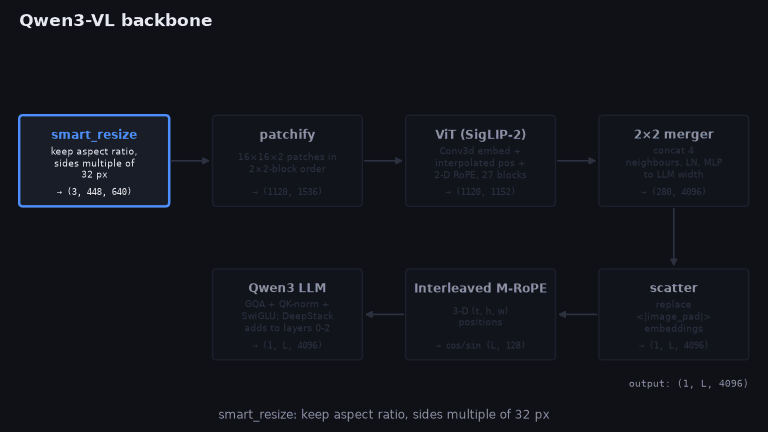

In [2]:
display(FilmCatalog.qwen3_vl_pipeline().show(FILMS / "qwen3_vl_pipeline.gif"))

### The real model vs the toy model in this notebook

The library defaults are the released vision tower (SigLIP-2 so400m: width 1152, 27 blocks, 16 heads)
and an 8B-sized text tower. We count their parameters on the `meta` device (no memory is allocated),
then build a **tiny** model with exactly the same structure for the step-by-step checks.

In [3]:
from transformers import Qwen3VLVisionConfig
from transformers.models.qwen3_vl.modeling_qwen3_vl import Qwen3VLVisionModel

with torch.device("meta"):
    real_vision = Qwen3VLVisionModel(Qwen3VLVisionConfig())
vc = real_vision.config
groups = {"patch embed": real_vision.patch_embed, "abs. position table": real_vision.pos_embed,
          f"{vc.depth} ViT blocks": real_vision.blocks, "main merger": real_vision.merger,
          f"{len(vc.deepstack_visual_indexes)} DeepStack mergers": real_vision.deepstack_merger_list}
for name, module in groups.items():
    print(f"{name:<22} {sum(p.numel() for p in module.parameters()) / 1e6:8.1f} M")
print(f"{'vision tower total':<22} {sum(p.numel() for p in real_vision.parameters()) / 1e6:8.1f} M")
print(f"\npatch {vc.patch_size}, temporal patch {vc.temporal_patch_size}, merge {vc.spatial_merge_size}, "
      f"width {vc.hidden_size}, heads {vc.num_heads}, DeepStack taps {list(vc.deepstack_visual_indexes)}, "
      f"position table {int(vc.num_position_embeddings ** 0.5)}² entries")

patch embed                 1.8 M
abs. position table         2.7 M
27 ViT blocks             411.5 M
main merger                37.8 M
3 DeepStack mergers       113.3 M
vision tower total        566.9 M

patch 16, temporal patch 2, merge 2, width 1152, heads 16, DeepStack taps [8, 16, 24], position table 48² entries


In [4]:
cfg = Qwen3VLConfig(
    vision_config=dict(depth=6, hidden_size=64, intermediate_size=128, num_heads=4, patch_size=16,
                       spatial_merge_size=2, temporal_patch_size=2, out_hidden_size=96,
                       num_position_embeddings=256, deepstack_visual_indexes=[1, 3, 4]),
    text_config=dict(vocab_size=320, hidden_size=96, intermediate_size=192, num_hidden_layers=4,
                     num_attention_heads=4, num_key_value_heads=2, head_dim=24,
                     rope_parameters={"rope_type": "default", "rope_theta": 5e5,
                                      "mrope_section": [4, 4, 4], "mrope_interleaved": True}),
    image_token_id=300, video_token_id=301, vision_start_token_id=302, vision_end_token_id=303)

torch.manual_seed(0)
model = Qwen3VLModel(cfg).eval()
with torch.no_grad():                       # move every weight off its init value so checks are meaningful
    for p in model.parameters():
        p.add_(0.05 * torch.randn_like(p))
V, T = model.visual, model.language_model
vcfg, tcfg = cfg.vision_config, cfg.text_config
print(f"toy model: {sum(p.numel() for p in model.parameters()) / 1e3:.0f} k parameters | "
      f"vision width {vcfg.hidden_size}, depth {vcfg.depth}, taps {vcfg.deepstack_visual_indexes} | "
      f"text width {tcfg.hidden_size}, {tcfg.num_hidden_layers} layers, "
      f"{tcfg.num_attention_heads} q-heads / {tcfg.num_key_value_heads} kv-heads, head_dim {tcfg.head_dim}")

toy model: 1043 k parameters | vision width 64, depth 6, taps [1, 3, 4] | text width 96, 4 layers, 4 q-heads / 2 kv-heads, head_dim 24


## Step 1: dynamic resolution with `smart_resize`

Fixed-resolution encoders (CLIP at 224 or 336) squash every image into one square. Qwen2-VL
introduced **native dynamic resolution**, and Qwen3-VL keeps it. The image keeps its aspect ratio, and
each side is rounded to a multiple of

$$\text{factor} = \text{patch\_size} \times \text{merge\_size} = 16 \times 2 = 32 \text{ px},$$

so that the image tiles exactly into 2×2 groups of 16-px patches. One 32×32 cell becomes **one LLM
token**. If the area falls outside `[min_pixels, max_pixels]`, both sides are scaled by the same
factor `β` and rounded again. The token count therefore follows the image: a thin receipt and a wide
panorama each get a grid that matches their shape.

In [5]:
def smart_resize(height, width, factor=32, min_pixels=64 * 32 * 32, max_pixels=1280 * 32 * 32):
    # Round each side to a multiple of `factor`; rescale both sides by β if the area is out of bounds.
    if max(height, width) / min(height, width) > 200:
        raise ValueError("aspect ratio must be < 200")
    h_bar, w_bar = round(height / factor) * factor, round(width / factor) * factor
    if h_bar * w_bar > max_pixels:                       # too big: shrink, rounding *down*
        beta = math.sqrt(height * width / max_pixels)
        h_bar = max(factor, math.floor(height / beta / factor) * factor)
        w_bar = max(factor, math.floor(width / beta / factor) * factor)
    elif h_bar * w_bar < min_pixels:                     # too small: enlarge, rounding *up*
        beta = math.sqrt(min_pixels / (height * width))
        h_bar = math.ceil(height * beta / factor) * factor
        w_bar = math.ceil(width * beta / factor) * factor
    return h_bar, w_bar

from transformers.models.qwen2_vl.image_processing_qwen2_vl import smart_resize as hf_smart_resize
for h, w in [(480, 640), (900, 300), (256, 1024), (4000, 3000), (20, 30), (1080, 1920)]:
    ours = smart_resize(h, w)
    ref = hf_smart_resize(h, w, factor=32, min_pixels=64 * 32 * 32, max_pixels=1280 * 32 * 32)
    assert ours == ref
    print(f"{h:>5}×{w:<5} → {ours[0]:>4}×{ours[1]:<4} = {ours[0] // 32:>2}×{ours[1] // 32:<2} grid "
          f"= {ours[0] * ours[1] // 1024:>4} LLM tokens   ✅ same as transformers")

  480×640   →  480×640  = 15×20 grid =  300 LLM tokens   ✅ same as transformers
  900×300   →  896×288  = 28×9  grid =  252 LLM tokens   ✅ same as transformers
  256×1024  →  256×1024 =  8×32 grid =  256 LLM tokens   ✅ same as transformers
 4000×3000  → 1312×960  = 41×30 grid = 1230 LLM tokens   ✅ same as transformers
   20×30    →  224×320  =  7×10 grid =   70 LLM tokens   ✅ same as transformers
 1080×1920  →  832×1504 = 26×47 grid = 1222 LLM tokens   ✅ same as transformers


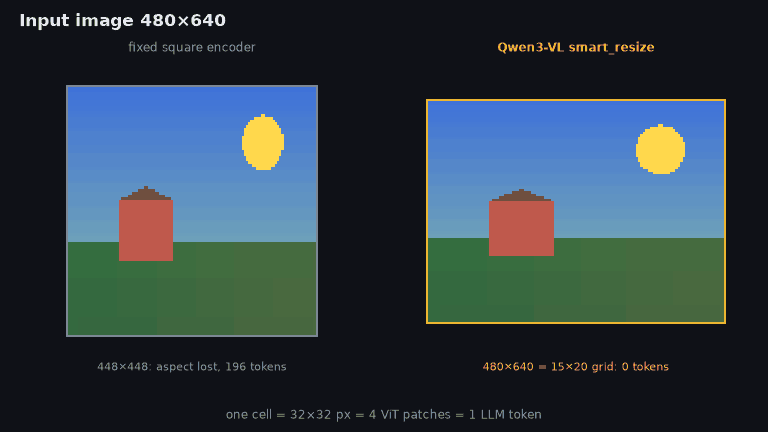

In [6]:
display(FilmCatalog.qwen3_vl_dynamic_resolution().show(FILMS / "qwen3_vl_dynamic_resolution.gif"))

## Step 2: patchify (16×16 pixels × 2 frames per patch, in 2×2-block order)

Qwen3-VL treats images and video the same way. A patch is a **16×16×2 space-time cube**. A still
image is repeated to fill the 2 frames, so an image has `grid_t = 1`. Each cube is flattened to
`3 · 2 · 16 · 16 = 1536` numbers.

The important detail is the **order** of the patches. The processor emits them *block-major*: the 4
patches of each 2×2 block are consecutive (row-major inside the block), then the next block. The
2×2 merger in step 6 is then a plain `view(-1, 4·C)`, with no gather needed. The probe below runs
the real `patchify` on an image whose pixels hold their own patch index, then reads the order back.

sequence position → raster patch index, grouped by merged token:
  token 0: patches [0, 1, 6, 7]
  token 1: patches [2, 3, 8, 9]
  token 2: patches [4, 5, 10, 11]
  token 3: patches [12, 13, 18, 19]
  token 4: patches [14, 15, 20, 21]
  token 5: patches [16, 17, 22, 23]


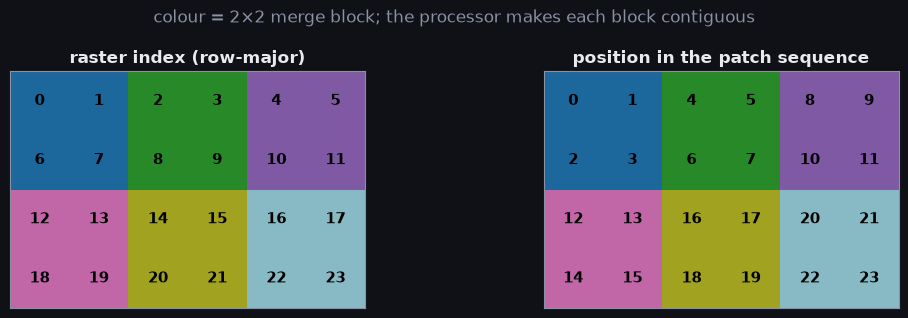

In [7]:
grid_h, grid_w = 4, 6
order = MergeMappingProbe.qwen3_vl_merge(grid_h, grid_w, merge=2)
print("sequence position → raster patch index, grouped by merged token:")
for k, group in enumerate(order):
    print(f"  token {k}: patches {group}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
raster = np.arange(grid_h * grid_w).reshape(grid_h, grid_w)
seq_pos = np.empty_like(raster); seq_pos.flat[np.array(order).ravel()] = np.arange(raster.size)
for ax, data, title in [(axes[0], raster, "raster index (row-major)"),
                        (axes[1], seq_pos, "position in the patch sequence")]:
    ax.imshow(np.array(order).ravel().argsort().reshape(grid_h, grid_w) // 4, cmap="tab20", alpha=0.85)
    for (r, c), v in np.ndenumerate(data):
        ax.text(c, r, v, ha="center", va="center", fontsize=11, color="black", weight="bold")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("colour = 2×2 merge block; the processor makes each block contiguous", color="#8a91a3")
plt.tight_layout(); plt.show()

Now the full preprocessing from scratch: rescale to `[0, 1]`, normalise, repeat the frame, and cut
cubes in block-major order. We compare it with `Qwen2VLImageProcessor` (Qwen3-VL's own processor
config uses mean = std = 0.5). The inputs are two images of different shapes: a landscape 64×96
and a portrait 96×64. Both sizes are already multiples of 32, so the resize step is the identity
and the comparison is exact.

In [8]:
MEAN = STD = (0.5, 0.5, 0.5)
processor = Qwen2VLImageProcessor(patch_size=16, merge_size=2, temporal_patch_size=2, image_mean=MEAN,
                                  image_std=STD, size={"shortest_edge": 32 * 32, "longest_edge": 32 * 32 * 64})

def patchify(image_uint8, patch=16, merge=2, temporal=2):
    # (H, W, 3) uint8 -> ((H/16)·(W/16), 3·2·16·16) block-major patches and grid (t, h, w).
    x = torch.from_numpy(image_uint8).permute(2, 0, 1).float() / 255.0
    x = (x - torch.tensor(MEAN)[:, None, None]) / torch.tensor(STD)[:, None, None]
    C, H, W = x.shape
    gh, gw = H // patch, W // patch
    x = x.reshape(C, gh // merge, merge, patch, gw // merge, merge, patch)
    x = x.permute(1, 4, 2, 5, 0, 3, 6)                    # (bh, bw, mh, mw, C, ph, pw): block-major
    x = x.unsqueeze(5).expand(-1, -1, -1, -1, -1, temporal, -1, -1)   # repeat the still frame
    return x.reshape(gh * gw, C * temporal * patch * patch), (1, gh, gw)

rng = np.random.default_rng(0)
images = [rng.integers(0, 256, (64, 96, 3), dtype=np.uint8), rng.integers(0, 256, (96, 64, 3), dtype=np.uint8)]
ours = [patchify(im) for im in images]
pixel_values = torch.cat([p for p, _ in ours])
grid_thw = torch.tensor([g for _, g in ours])

ref = processor(images=images, return_tensors="pt")
check("patchified pixel_values", pixel_values, ref["pixel_values"])
check("image_grid_thw", grid_thw, ref["image_grid_thw"], atol=0)
print("grid_thw per image:", grid_thw.tolist(), "→ patches:", grid_thw.prod(-1).tolist(),
      "→ LLM tokens:", (grid_thw.prod(-1) // 4).tolist())

✅ patchified pixel_values                      shape (48, 1536)         max|Δ| = 5.91e-08
✅ image_grid_thw                               shape (2, 3)             max|Δ| = 0.00e+00
grid_thw per image: [[1, 4, 6], [1, 6, 4]] → patches: [24, 24] → LLM tokens: [6, 6]


## Step 3: the patch embedding, a Conv3d that is really a Linear

`Qwen3VLVisionPatchEmbed` is a `Conv3d(3 → C, kernel = stride = (2, 16, 16))`. Each input cube is
exactly one kernel window, so the convolution is a **matrix multiply** of the flattened 1536-vector
with the reshaped kernel. This is why the processor can hand over flat patches of variable count, and
why exporters turn the layer into a single GEMM.

In [9]:
W_pe = V.patch_embed.proj.weight                   # (C, 3, 2, 16, 16)
b_pe = V.patch_embed.proj.bias
with torch.no_grad():
    ours = pixel_values @ W_pe.reshape(W_pe.shape[0], -1).T + b_pe
    ref = V.patch_embed(pixel_values)
check("patch embedding (Linear form)", ours, ref)

✅ patch embedding (Linear form)                shape (48, 64)           max|Δ| = 8.82e-06


## Step 4: where is each patch? Two position signals

Qwen3-VL's ViT gets position information **twice**:

1. **An absolute, learned table** inherited from SigLIP-2: `num_position_embeddings = 2304 = 48²`
   entries for a 48×48 reference grid. For an image with an `h×w` patch grid, the table is
   **bilinearly resampled** (`align_corners=True`) to `h×w` and added to the patch embeddings. The
   result is then reordered block-major, like the patches.
2. **A 2-D rotary embedding inside every attention layer.** Half of each head's rotary frequencies
   rotate with the patch **row**, the other half with the **column**. Attention scores then depend on
   the *relative* 2-D offset between patches, which is what lets the model generalise to resolutions
   it never saw.

### 4a. The interpolated absolute table

✅ interpolated absolute position embedding     shape (48, 64)           max|Δ| = 0.00e+00


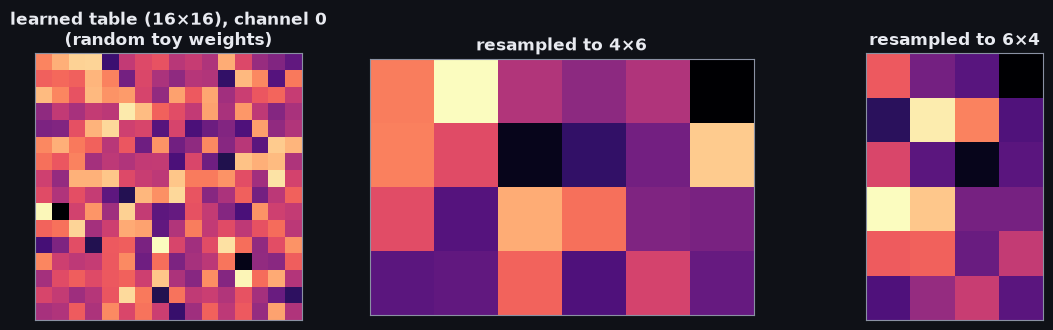

In [10]:
side = int(vcfg.num_position_embeddings ** 0.5)
def interpolated_pos_embed(table, grid_thw, merge=2):
    # Resample the (side², C) learned table to each image's (h, w) grid; return block-major rows.
    out = []
    C = table.shape[1]
    grid = table.reshape(side, side, C).permute(2, 0, 1)[None]          # (1, C, side, side)
    for t, h, w in grid_thw.tolist():
        pos = F.interpolate(grid, size=(h, w), mode="bilinear", align_corners=True)[0]   # (C, h, w)
        pos = pos.permute(1, 2, 0).reshape(h // merge, merge, w // merge, merge, C)
        pos = pos.permute(0, 2, 1, 3, 4).reshape(h * w, C)               # block-major, like the patches
        out.append(pos.repeat(t, 1))
    return torch.cat(out)

from transformers.vision_utils import get_vision_interpolation_indices_and_weights
with torch.no_grad():
    ours_pos = interpolated_pos_embed(V.pos_embed.weight, grid_thw)
    idx, wts = get_vision_interpolation_indices_and_weights(grid_thw, num_grid_per_side=side, mode="bilinear",
                                                           align_corners=True, spatial_merge_size=2)
    ref_pos = (V.pos_embed(idx) * wts[:, :, None]).sum(1)
check("interpolated absolute position embedding", ours_pos, ref_pos)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
table = V.pos_embed.weight.detach().reshape(side, side, -1)[..., 0]
axes[0].imshow(table, cmap="magma"); axes[0].set_title(f"learned table ({side}×{side}), channel 0\n(random toy weights)")
for ax, (t, h, w) in zip(axes[1:], grid_thw.tolist()):
    grid = table[None, None]
    ax.imshow(F.interpolate(grid, size=(h, w), mode="bilinear", align_corners=True)[0, 0], cmap="magma")
    ax.set_title(f"resampled to {h}×{w}")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 4b. 2-D rotary position embedding in the ViT

With head dimension $d$, the vision rotary module has $d/4$ inverse frequencies
$\omega_k = 10000^{-4k/d}$. A patch at grid position $(r, c)$ gets the angle vector

$$\theta(r, c) = [\, r\,\omega_0, \dots, r\,\omega_{d/4-1},\; c\,\omega_0, \dots, c\,\omega_{d/4-1} \,]$$

which is duplicated to length $d$ for `rotate_half`. The rotation obeys $R(\theta_i)^\top R(\theta_j) = R(\theta_j - \theta_i)$,
so $q_i \cdot k_j$ depends only on the offset $(r_j - r_i,\; c_j - c_i)$. Rows and columns come from the
same block-major ordering as the patches.

✅ vision RoPE cos                              shape (48, 16)           max|Δ| = 0.00e+00
✅ vision RoPE sin                              shape (48, 16)           max|Δ| = 0.00e+00


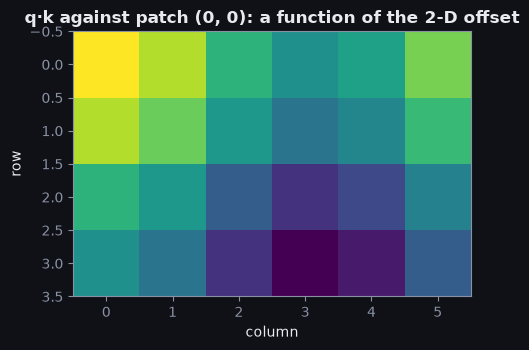

In [11]:
def rotate_half(x):
    x1, x2 = x[..., : x.shape[-1] // 2], x[..., x.shape[-1] // 2:]
    return torch.cat((-x2, x1), dim=-1)

def vision_rope(grid_thw, head_dim, merge=2, theta=10000.0):
    # cos/sin of shape (N, head_dim) from block-major (row, col) patch coordinates.
    inv_freq = 1.0 / theta ** (torch.arange(0, head_dim // 2, 2).float() / (head_dim // 2))   # d/4 freqs
    coords = []
    for t, h, w in grid_thw.tolist():
        rows, cols = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
        rc = torch.stack([rows, cols], -1).reshape(h // merge, merge, w // merge, merge, 2)
        coords.append(rc.permute(0, 2, 1, 3, 4).reshape(-1, 2).repeat(t, 1))
    coords = torch.cat(coords).float()                                   # (N, 2) = (row, col)
    angles = (coords[..., None] * inv_freq).flatten(1)                   # (N, d/2): rows then cols
    emb = torch.cat([angles, angles], -1)                                # (N, d) for rotate_half
    return emb.cos(), emb.sin(), coords

head_dim_v = vcfg.hidden_size // vcfg.num_heads
cos_v, sin_v, coords = vision_rope(grid_thw, head_dim_v)
from transformers.vision_utils import get_vision_position_ids
ref_angles = V.rotary_pos_emb(get_vision_position_ids(grid_thw, 2))
ref_emb = torch.cat([ref_angles, ref_angles], -1)
check("vision RoPE cos", cos_v, ref_emb.cos()); check("vision RoPE sin", sin_v, ref_emb.sin())

# Relative-position property: rotate the same vector to every patch of image 0 and score it against
# the copy at patch (0, 0). The score depends only on the (row, col) offset.
q = torch.ones(head_dim_v)
def rotated(vec, i): return vec * cos_v[i] + rotate_half(vec) * sin_v[i]
scores = torch.stack([rotated(q, i) @ rotated(q, 0) for i in range(24)])
fig, ax = plt.subplots(figsize=(5.5, 3.6))
img = np.zeros((4, 6)); img[coords[:24, 0].long(), coords[:24, 1].long()] = scores.numpy()
ax.imshow(img, cmap="viridis"); ax.set_title("q·k against patch (0, 0): a function of the 2-D offset")
ax.set_xlabel("column"); ax.set_ylabel("row"); plt.tight_layout(); plt.show()

## Step 5: one ViT block, and packed attention over several images

Every image in a batch has a different number of patches. Qwen3-VL **packs** all patches of all
images into one sequence of length $N = \sum_i h_i w_i$, with no padding. Attention must not leak between
images, so it runs on segments delimited by `cu_seqlens` (cumulative sequence lengths). FlashAttention
handles the segments natively (varlen); the eager path splits the sequence. The result is a
**block-diagonal** attention pattern.

The block is a standard pre-LayerNorm transformer block: `x + Attn(LN(x))`, then `x + MLP(LN(x))`,
with a fused `qkv` projection, RoPE applied to `q` and `k`, and a `gelu(tanh)` MLP.

cu_seqlens = [0, 24, 48] (segment boundaries in the packed sequence)
✅ ViT block 0                                  shape (48, 64)           max|Δ| = 2.38e-07


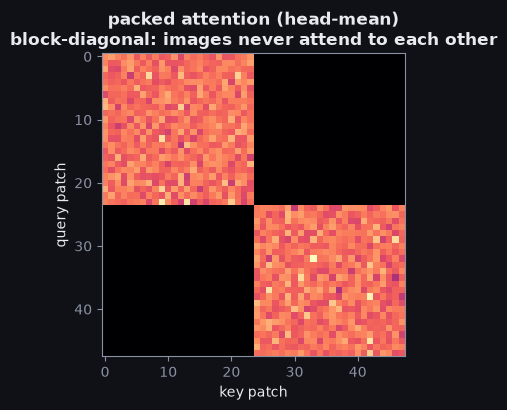

In [12]:
cu_seqlens = F.pad(grid_thw.prod(-1).cumsum(0), (1, 0))
print("cu_seqlens =", cu_seqlens.tolist(), "(segment boundaries in the packed sequence)")

def vision_block(blk, x, cos, sin, cu_seqlens, return_attn=False):
    heads, N = vcfg.num_heads, x.shape[0]
    h = F.layer_norm(x, (x.shape[-1],), blk.norm1.weight, blk.norm1.bias, eps=1e-6)
    q, k, v = blk.attn.qkv(h).reshape(N, 3, heads, -1).unbind(1)          # each (N, heads, d)
    q = q * cos[:, None] + rotate_half(q) * sin[:, None]
    k = k * cos[:, None] + rotate_half(k) * sin[:, None]
    out, maps = torch.zeros_like(q), []
    for s, e in zip(cu_seqlens[:-1].tolist(), cu_seqlens[1:].tolist()):    # one image at a time
        att = torch.einsum("qhd,khd->hqk", q[s:e], k[s:e]) / math.sqrt(q.shape[-1])
        att = att.softmax(-1)
        out[s:e] = torch.einsum("hqk,khd->qhd", att, v[s:e])
        maps.append(att)
    x = x + blk.attn.proj(out.reshape(N, -1))
    h = F.layer_norm(x, (x.shape[-1],), blk.norm2.weight, blk.norm2.bias, eps=1e-6)
    x = x + blk.mlp.linear_fc2(F.gelu(blk.mlp.linear_fc1(h), approximate="tanh"))
    return (x, maps) if return_attn else x

with torch.no_grad():
    x0 = V.patch_embed(pixel_values) + ref_pos
    ours_blk, maps = vision_block(V.blocks[0], x0, cos_v, sin_v, cu_seqlens, return_attn=True)
    ref_blk = V.blocks[0](x0, cu_seqlens=cu_seqlens.int(), position_embeddings=(ref_emb.cos(), ref_emb.sin()))
check("ViT block 0", ours_blk, ref_blk)

full = torch.zeros(len(x0), len(x0))
for (s, e), m in zip(zip(cu_seqlens[:-1].tolist(), cu_seqlens[1:].tolist()), maps):
    full[s:e, s:e] = m.mean(0)
plt.figure(figsize=(4.6, 4.2)); plt.imshow(full, cmap="magma")
plt.title("packed attention (head-mean)\nblock-diagonal: images never attend to each other")
plt.xlabel("key patch"); plt.ylabel("query patch"); plt.tight_layout(); plt.show()

## Step 6: the 2×2 patch merger, from 4 ViT patches to 1 LLM token

After the last block, `Qwen3VLVisionPatchMerger` turns every 2×2 block into one token:

$$\text{LN}_{C}(x) \;\xrightarrow{\;\text{view}(-1,\,4C)\;}\; \text{Linear}_{4C\to4C} \to \text{GELU} \to \text{Linear}_{4C \to D_\text{LLM}}$$

Because the patches are already block-major (step 2), the "concat 4 neighbours" is a free `view`.
The main merger normalises **before** the concat (per patch, width C). The DeepStack mergers in
step 7 normalise **after** it (width 4C, `use_postshuffle_norm=True`). This is a 4× token
reduction: a 448×640 image is 1120 ViT patches but only 280 LLM tokens.

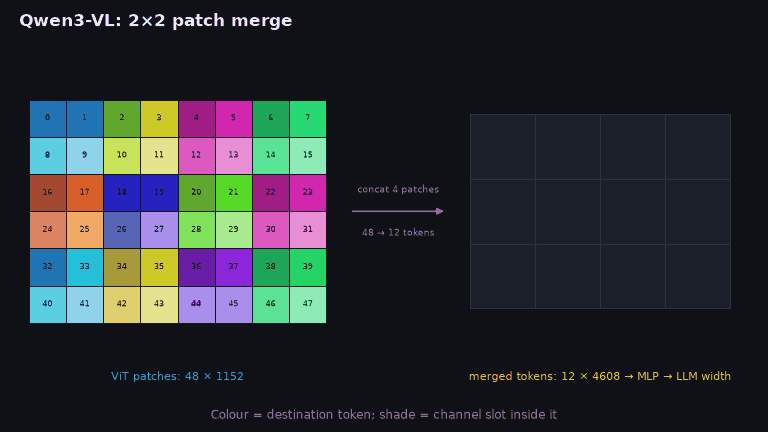

In [13]:
display(FilmCatalog.qwen3_vl_patch_merge().show(FILMS / "qwen3_vl_patch_merge.gif"))

In [14]:
def patch_merger(merger, x, postshuffle):
    C4 = merger.linear_fc1.in_features
    if postshuffle:
        x = F.layer_norm(x.view(-1, C4), (C4,), merger.norm.weight, merger.norm.bias, eps=1e-6)
    else:
        x = F.layer_norm(x, (x.shape[-1],), merger.norm.weight, merger.norm.bias, eps=1e-6).view(-1, C4)
    return merger.linear_fc2(F.gelu(merger.linear_fc1(x)))

with torch.no_grad():
    check("main merger", patch_merger(V.merger, ours_blk, False), V.merger(ours_blk))
    check("DeepStack merger 0 (post-shuffle LN)", patch_merger(V.deepstack_merger_list[0], ours_blk, True),
          V.deepstack_merger_list[0](ours_blk))

✅ main merger                                  shape (12, 96)           max|Δ| = 0.00e+00
✅ DeepStack merger 0 (post-shuffle LN)         shape (12, 96)           max|Δ| = 0.00e+00


## Step 7: DeepStack, multi-level vision features without extra tokens

A classic LLaVA-style VLM feeds the LLM only the **last** ViT layer, at the input. Qwen3-VL also taps
intermediate ViT blocks (8, 16 and 24 in the released model; 1, 3 and 4 in our toy). Each tap has its
own merger. Its output is **added to the LLM hidden states at the image-token positions**, right
after decoder layers 0, 1 and 2 (DeepStack; Meng et al., 2024, [arXiv:2406.04334](https://arxiv.org/abs/2406.04334)).
Low-level detail (edges, small text) thus reaches the LLM directly, while the sequence length is
unchanged.

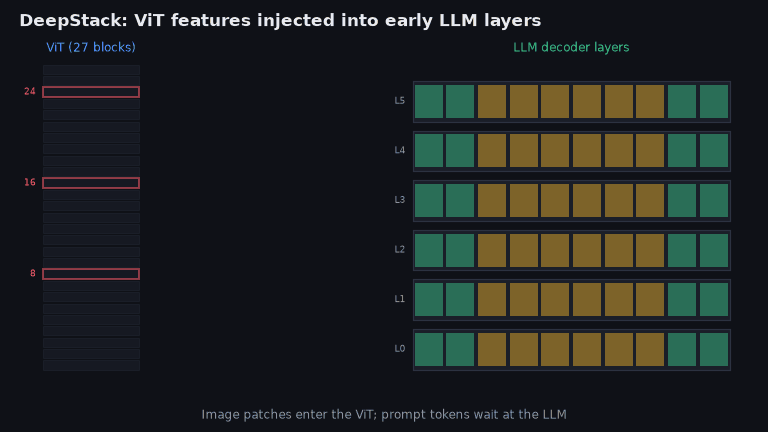

In [15]:
display(FilmCatalog.qwen3_vl_deepstack().show(FILMS / "qwen3_vl_deepstack.gif"))

✅ vision tower: merged image tokens            shape (12, 96)           max|Δ| = 1.61e-06
✅ vision tower: DeepStack feature 0 (block 1)  shape (12, 96)           max|Δ| = 1.46e-06
✅ vision tower: DeepStack feature 1 (block 3)  shape (12, 96)           max|Δ| = 1.43e-06
✅ vision tower: DeepStack feature 2 (block 4)  shape (12, 96)           max|Δ| = 1.64e-06


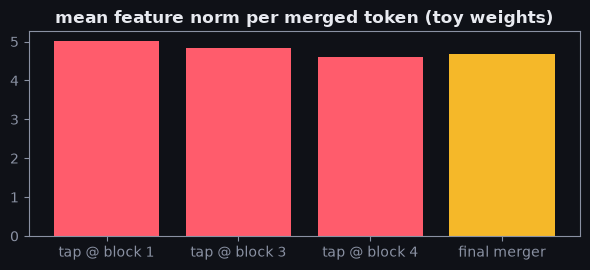

In [16]:
def vision_tower(pixel_values, grid_thw, taps=None):
    # Full Qwen3-VL vision forward from scratch: returns (merged tokens, [DeepStack features]).
    taps = vcfg.deepstack_visual_indexes if taps is None else taps
    cos, sin, _ = vision_rope(grid_thw, head_dim_v)
    cu = F.pad(grid_thw.prod(-1).cumsum(0), (1, 0))
    W = V.patch_embed.proj.weight
    x = pixel_values @ W.reshape(W.shape[0], -1).T + V.patch_embed.proj.bias
    x = x + interpolated_pos_embed(V.pos_embed.weight, grid_thw)
    deepstack = []
    for i, blk in enumerate(V.blocks):
        x = vision_block(blk, x, cos, sin, cu)
        if i in taps:
            k = vcfg.deepstack_visual_indexes.index(i)
            deepstack.append(patch_merger(V.deepstack_merger_list[k], x, postshuffle=True))
    return patch_merger(V.merger, x, postshuffle=False), deepstack

with torch.no_grad():
    image_embeds, deepstack = vision_tower(pixel_values, grid_thw)
    ref = V(pixel_values, grid_thw=grid_thw)
check("vision tower: merged image tokens", image_embeds, ref.pooler_output)
for k, (a, b) in enumerate(zip(deepstack, ref.deepstack_features)):
    check(f"vision tower: DeepStack feature {k} (block {vcfg.deepstack_visual_indexes[k]})", a, b)

norms = [d.norm(dim=-1).mean().item() for d in deepstack] + [image_embeds.norm(dim=-1).mean().item()]
labels = [f"tap @ block {i}" for i in vcfg.deepstack_visual_indexes] + ["final merger"]
plt.figure(figsize=(6, 2.8)); plt.bar(labels, norms, color=["#ff5c6c"] * len(deepstack) + ["#f5b829"])
plt.title("mean feature norm per merged token (toy weights)"); plt.tight_layout(); plt.show()

## Step 8: where the image goes in the prompt

The chat template wraps each image in `<|vision_start|> … <|vision_end|>`, and the processor
expands one `<|image_pad|>` into **as many placeholders as merged tokens** ($h\,w/4$). Inside the
model, the placeholder embeddings are overwritten with the merger output by `masked_scatter`, in
sequence order. The images' tokens are concatenated in the order the images appear.

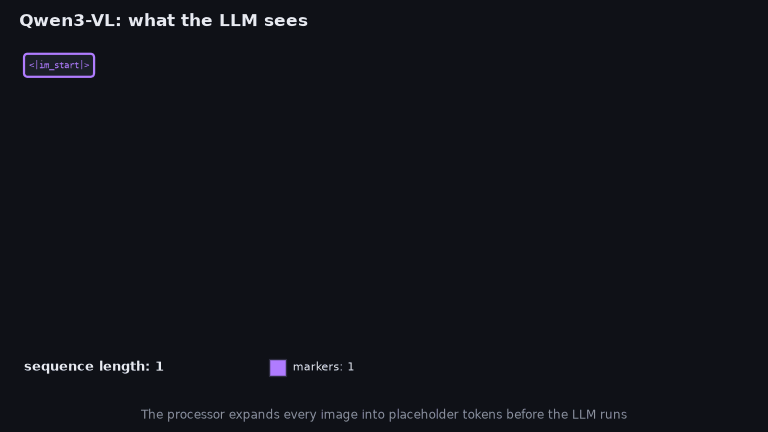

In [17]:
display(FilmCatalog.qwen3_vl_token_stream().show(FILMS / "qwen3_vl_token_stream.gif"))

In [18]:
n_tokens = (grid_thw.prod(-1) // 4).tolist()                     # merged tokens per image
VS, VE, PAD = cfg.vision_start_token_id, cfg.vision_end_token_id, cfg.image_token_id
ids = [11, 12, VS, *[PAD] * n_tokens[0], VE, 13, 14, VS, *[PAD] * n_tokens[1], VE, 15, 16, 17]
input_ids = torch.tensor([ids])
mm_token_type_ids = (input_ids == PAD).int()                     # 0 text, 1 image, 2 video
print("sequence:", " ".join({VS: "<vs>", VE: "<ve>", PAD: "▣"}.get(t, str(t)) for t in ids))

with torch.no_grad():
    embeds = T.embed_tokens(input_ids)
    image_mask = input_ids == PAD
    ours_embeds = embeds.clone()
    ours_embeds[image_mask] = image_embeds                         # sequence-order scatter
    ref_embeds = embeds.masked_scatter(image_mask[..., None].expand_as(embeds), image_embeds)
check("placeholder scatter (masked_scatter)", ours_embeds, ref_embeds)

sequence: 11 12 <vs> ▣ ▣ ▣ ▣ ▣ ▣ <ve> 13 14 <vs> ▣ ▣ ▣ ▣ ▣ ▣ <ve> 15 16 17
✅ placeholder scatter (masked_scatter)         shape (1, 23, 96)        max|Δ| = 0.00e+00


## Step 9: interleaved M-RoPE, 3-D positions for the LLM

A text-only LLM gives token $i$ the position $i$. Qwen-VL models give each token a **triple**
$(t, h, w)$:

* **text** tokens: $t = h = w = p$, and $p$ advances by 1;
* **image** tokens on a merged $H \times W$ grid starting at $p$: $t = p$, $h = p + \text{row}$, $w = p + \text{col}$;
  afterwards $p$ advances by $\max(H, W)$, **not** $H \cdot W$;
* **video**: Qwen3-VL puts textual timestamps (`<t seconds>`) between frames and gives each frame its own
  $t$, instead of Qwen2.5-VL's absolute-time position ids.

The rotary frequencies of each head are split between the three axes (`mrope_section = [24, 20, 20]`
pairs for head_dim 128). Qwen2/2.5-VL assigned **contiguous chunks**, so time only got the
highest-frequency (fastest) rotations and width only the slowest. Qwen3-VL **interleaves** them
(`t h w t h w …`), so every axis spans the full frequency range. That matters for long videos and
large images.

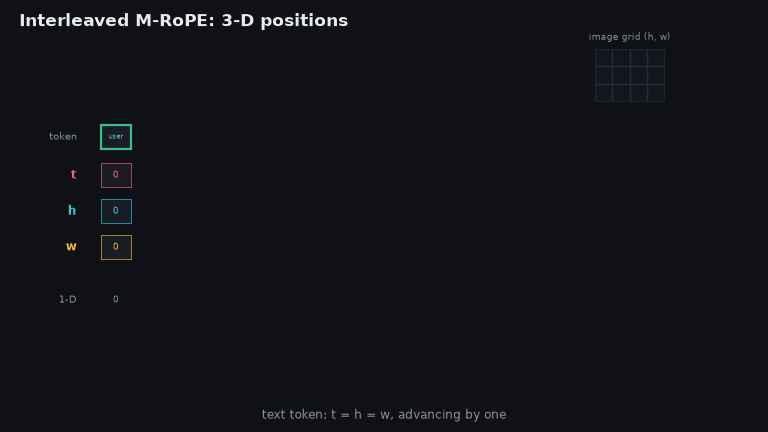

In [19]:
display(FilmCatalog.qwen3_vl_mrope().show(FILMS / "qwen3_vl_mrope.gif"))

✅ M-RoPE position ids (t, h, w)                shape (3, 1, 23)         max|Δ| = 0.00e+00
rope delta: ours -6, transformers -6  (sequence length 23, last position 16)


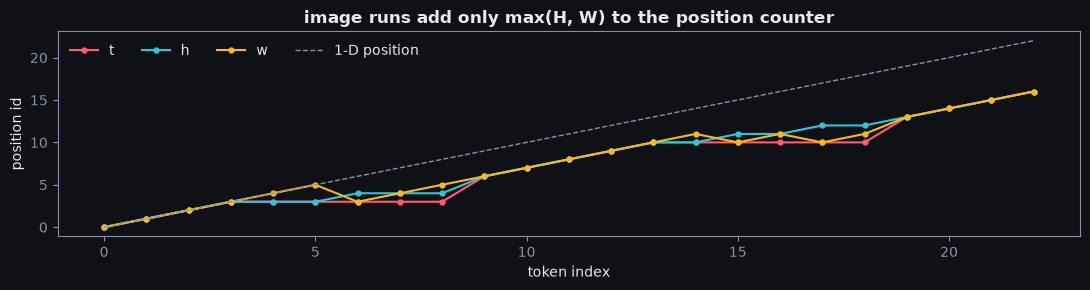

In [20]:
def rope_index(input_ids, mm_token_type_ids, grid_thw, merge=2):
    # 3-D (t, h, w) position ids for one sequence, following Qwen3VLModel.get_rope_index.
    pos, p, images = [], 0, iter(grid_thw.tolist())
    types = mm_token_type_ids[0].tolist()
    i = 0
    while i < len(types):
        j = i
        while j < len(types) and types[j] == types[i]:
            j += 1                                                      # [i, j) is one modality run
        if types[i] == 0:
            run = torch.arange(p, p + j - i)
            pos.append(torch.stack([run, run, run]))
            p += j - i
        else:
            t, h, w = next(images)
            gh, gw = h // merge, w // merge
            tt, hh, ww = torch.meshgrid(torch.arange(t), torch.arange(gh), torch.arange(gw), indexing="ij")
            pos.append(torch.stack([tt.flatten() + p, hh.flatten() + p, ww.flatten() + p]))
            p += max(gh, gw)
        i = j
    pos = torch.cat(pos, 1)[:, None]                                    # (3, batch=1, L)
    delta = pos.max() + 1 - input_ids.shape[1]                          # used during decoding
    return pos, delta

ours_pos, ours_delta = rope_index(input_ids, mm_token_type_ids, grid_thw)
ref_pos, ref_delta = model.get_rope_index(input_ids, mm_token_type_ids, image_grid_thw=grid_thw)
check("M-RoPE position ids (t, h, w)", ours_pos, ref_pos, atol=0)
print(f"rope delta: ours {ours_delta.item()}, transformers {ref_delta.item()}  "
      f"(sequence length {input_ids.shape[1]}, last position {ours_pos.max().item()})")

fig, ax = plt.subplots(figsize=(11, 3))
for row, (name, colour) in enumerate([("t", "#ff5c6c"), ("h", "#33c3d6"), ("w", "#f5b829")]):
    ax.plot(ours_pos[row, 0], "o-", ms=3.5, color=colour, label=name)
ax.plot(np.arange(input_ids.shape[1]), "--", color="#8a91a3", lw=1, label="1-D position")
ax.set_xlabel("token index"); ax.set_ylabel("position id"); ax.legend(ncol=4, frameon=False)
ax.set_title("image runs add only max(H, W) to the position counter")
plt.tight_layout(); plt.show()

In [21]:
def mrope_cos_sin(position_ids, head_dim, theta, section):
    # Interleaved M-RoPE: frequency pair k takes its angle from axis k % 3 (t, h, w) within the sections.
    inv_freq = 1.0 / theta ** (torch.arange(0, head_dim, 2).float() / head_dim)       # (d/2,)
    freqs = position_ids[..., None].float() * inv_freq                                # (3, B, L, d/2)
    out = freqs[0].clone()                                                            # default: t
    out[..., 1: section[1] * 3: 3] = freqs[1][..., 1: section[1] * 3: 3]              # h on 1, 4, 7, …
    out[..., 2: section[2] * 3: 3] = freqs[2][..., 2: section[2] * 3: 3]              # w on 2, 5, 8, …
    emb = torch.cat([out, out], -1)
    return emb.cos(), emb.sin()

rp = tcfg.rope_parameters
cos_t, sin_t = mrope_cos_sin(ours_pos, tcfg.head_dim, rp["rope_theta"], rp["mrope_section"])
ref_cos, ref_sin = T.rotary_emb(embeds, ref_pos)
check("interleaved M-RoPE cos", cos_t, ref_cos); check("interleaved M-RoPE sin", sin_t, ref_sin)

✅ interleaved M-RoPE cos                       shape (1, 23, 24)        max|Δ| = 0.00e+00
✅ interleaved M-RoPE sin                       shape (1, 23, 24)        max|Δ| = 0.00e+00


## Step 10: the Qwen3 decoder layer, with DeepStack injection, end to end

Each Qwen3 decoder layer is pre-norm: RMSNorm, then attention, then a residual; RMSNorm, then a
SwiGLU MLP, then a residual. Two details set it apart from Llama:

* **QK-norm:** an RMSNorm over the head dimension is applied to every query and key head before RoPE.
  This stabilises attention logits, and Qwen3 drops the QKV biases Qwen2 used.
* **GQA:** fewer key/value heads than query heads (2 vs 4 in the toy, 8 vs 32 in the 8B model). The
  KV heads are shared by groups of query heads.

After layers `0 … len(deepstack)-1`, the DeepStack features are added at the image positions. The
cell below runs the **entire backbone from scratch** (vision tower, scatter, M-RoPE, decoder,
DeepStack) and compares the final hidden states with `Qwen3VLModel.forward`.

In [22]:
def rms_norm(x, weight, eps):
    return weight * (x.float() * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + eps)).to(x.dtype)

def decoder_layer(layer, x, cos, sin):
    B, L, _ = x.shape
    H, KV, d, eps = tcfg.num_attention_heads, tcfg.num_key_value_heads, tcfg.head_dim, tcfg.rms_norm_eps
    a = layer.self_attn
    h = rms_norm(x, layer.input_layernorm.weight, eps)
    q = rms_norm(a.q_proj(h).view(B, L, H, d), a.q_norm.weight, eps).transpose(1, 2)    # QK-norm
    k = rms_norm(a.k_proj(h).view(B, L, KV, d), a.k_norm.weight, eps).transpose(1, 2)
    v = a.v_proj(h).view(B, L, KV, d).transpose(1, 2)
    q = q * cos[:, None] + rotate_half(q) * sin[:, None]
    k = k * cos[:, None] + rotate_half(k) * sin[:, None]
    k, v = k.repeat_interleave(H // KV, 1), v.repeat_interleave(H // KV, 1)              # GQA
    scores = q @ k.transpose(-1, -2) / math.sqrt(d)
    scores = scores.masked_fill(torch.ones(L, L, dtype=torch.bool).triu(1), float("-inf"))
    attn = scores.softmax(-1)
    x = x + a.o_proj((attn @ v).transpose(1, 2).reshape(B, L, H * d))
    h = rms_norm(x, layer.post_attention_layernorm.weight, eps)
    m = layer.mlp
    return x + m.down_proj(F.silu(m.gate_proj(h)) * m.up_proj(h)), attn

def qwen3_vl_backbone(input_ids, mm_token_type_ids, pixel_values, grid_thw, deepstack_on=True):
    image_embeds, deepstack = vision_tower(pixel_values, grid_thw, taps=None if deepstack_on else [])
    x = T.embed_tokens(input_ids).clone()
    image_mask = input_ids == cfg.image_token_id
    x[image_mask] = image_embeds
    pos, _ = rope_index(input_ids, mm_token_type_ids, grid_thw)
    cos, sin = mrope_cos_sin(pos, tcfg.head_dim, rp["rope_theta"], rp["mrope_section"])
    attn_maps = []
    for i, layer in enumerate(T.layers):
        x, attn = decoder_layer(layer, x, cos, sin)
        attn_maps.append(attn)
        if i < len(deepstack):
            x = x.clone(); x[image_mask] = x[image_mask] + deepstack[i]          # DeepStack injection
    return rms_norm(x, T.norm.weight, tcfg.rms_norm_eps), attn_maps

with torch.no_grad():
    ours_out, attn_maps = qwen3_vl_backbone(input_ids, mm_token_type_ids, pixel_values, grid_thw)
    ref_out = model(input_ids=input_ids, pixel_values=pixel_values, image_grid_thw=grid_thw,
                    mm_token_type_ids=mm_token_type_ids).last_hidden_state
check("FULL BACKBONE: last hidden state", ours_out, ref_out, atol=2e-5)

✅ FULL BACKBONE: last hidden state             shape (1, 23, 96)        max|Δ| = 3.22e-06


### What does DeepStack change, and what does the LLM attend to?

To isolate DeepStack, we re-run the backbone without the injections and measure how far each final
hidden state moves. Image tokens move most, because they receive the additions directly. Text tokens
*after* an image move as well, because they attend to the changed image states. Tokens before the
first image are untouched, because attention is causal. The right panel shows the last layer's
causal attention with the two image blocks shaded. The colour scale is a power law, so the
attention sink on token 0 does not wash out the rest.

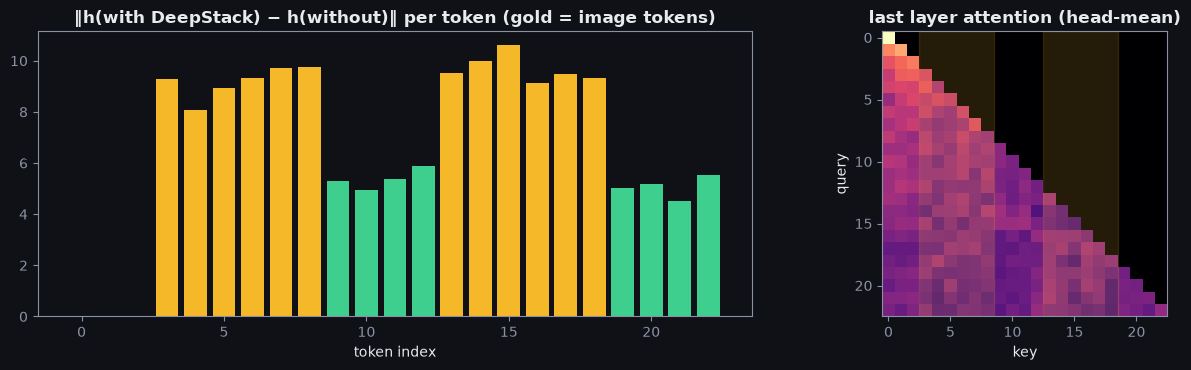

In [23]:
with torch.no_grad():
    plain_out, _ = qwen3_vl_backbone(input_ids, mm_token_type_ids, pixel_values, grid_thw,
                                     deepstack_on=False)
delta = (ours_out - plain_out).norm(dim=-1)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
colours = np.where(image_mask[0].numpy(), "#f5b829", "#3ecf8e")
axes[0].bar(np.arange(len(delta)), delta.numpy(), color=colours)
axes[0].set_title("‖h(with DeepStack) − h(without)‖ per token (gold = image tokens)")
axes[0].set_xlabel("token index")
from matplotlib.colors import PowerNorm
im = axes[1].imshow(attn_maps[-1][0].mean(0), cmap="magma", norm=PowerNorm(0.35))
axes[1].set_title("last layer attention (head-mean)"); axes[1].set_xlabel("key"); axes[1].set_ylabel("query")
for s, e in [(3, 3 + n_tokens[0]), (3 + n_tokens[0] + 4, 3 + n_tokens[0] + 4 + n_tokens[1])]:
    axes[1].axvspan(s - 0.5, e - 0.5, color="#f5b829", alpha=0.15)
plt.tight_layout(); plt.show()

## Summary

| Mechanism | Where | Why it matters |
|---|---|---|
| `smart_resize` (sides ÷ 32, area bounds) | processor | native aspect ratio; token count follows the image |
| 16×16×2 space-time patches, block-major | processor | images and video share one path; merge becomes a `view` |
| Conv3d patch embed ≡ Linear | ViT input | variable patch counts, one GEMM |
| interpolated 48² learned table + 2-D RoPE | ViT | absolute prior from SigLIP-2 plus relative 2-D geometry at any resolution |
| packed sequence + `cu_seqlens` | ViT attention | no padding; images never attend to each other |
| 2×2 merger (LN → concat → MLP) | ViT → LLM | 4× fewer LLM tokens |
| DeepStack (taps 8/16/24 → LLM layers 0/1/2) | LLM early layers | multi-level visual detail at zero extra tokens |
| interleaved M-RoPE (t, h, w) | LLM attention | 2-D/3-D positions; image costs max(H, W) positions; full frequency range per axis |
| QK-norm + GQA + SwiGLU | Qwen3 decoder | stable logits, smaller KV cache |

Every row was re-implemented above and matched `transformers` to within float32 rounding.

### Optional: the same checks on the real weights

Set `RUN_PRETRAINED = True` to download `Qwen/Qwen3-VL-2B-Instruct` (about 4.5 GB) and repeat the
vision-tower and full-backbone checks on a real image. The from-scratch functions above read their
weights from the model objects (`V`, `T`, `cfg`), so they are rebound to the real model.

In [24]:
RUN_PRETRAINED = False
if RUN_PRETRAINED:
    from transformers import AutoProcessor, Qwen3VLForConditionalGeneration
    from hale_vlm.visualization.backbone_films import SyntheticScene
    repo = "Qwen/Qwen3-VL-2B-Instruct"
    real = Qwen3VLForConditionalGeneration.from_pretrained(repo, dtype=torch.float32).eval()
    proc = AutoProcessor.from_pretrained(repo)
    model, V, T, cfg = real.model, real.model.visual, real.model.language_model, real.config
    vcfg, tcfg = cfg.vision_config, cfg.text_config
    rp, head_dim_v, side = tcfg.rope_parameters, vcfg.hidden_size // vcfg.num_heads, int(vcfg.num_position_embeddings ** 0.5)
    scene = (SyntheticScene.render(448, 640) * 255).astype(np.uint8)
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "Describe the scene."}]}]
    batch = proc(text=[proc.apply_chat_template(messages, add_generation_prompt=True)], images=[scene],
                 return_tensors="pt")
    with torch.no_grad():
        ours_out, _ = qwen3_vl_backbone(batch["input_ids"], batch["mm_token_type_ids"],
                                        batch["pixel_values"], batch["image_grid_thw"])
        ref_out = model(**batch).last_hidden_state
    check("REAL Qwen3-VL-2B backbone", ours_out, ref_out, atol=5e-3)

## References

* Qwen team. **Qwen3-VL** model cards and code: <https://github.com/QwenLM/Qwen3-VL>, <https://huggingface.co/Qwen>.
* P. Wang et al. **Qwen2-VL**: naive dynamic resolution and M-RoPE, 2024. [arXiv:2409.12191](https://arxiv.org/abs/2409.12191)
* L. Meng et al. **DeepStack**: deeply stacking visual tokens is surprisingly simple and effective for LMMs, 2024. [arXiv:2406.04334](https://arxiv.org/abs/2406.04334)
* M. Tschannen et al. **SigLIP 2**, 2025. [arXiv:2502.14786](https://arxiv.org/abs/2502.14786)
* J. Su et al. **RoFormer** (rotary position embedding), 2021. [arXiv:2104.09864](https://arxiv.org/abs/2104.09864)
* 🤗 `transformers` reference implementation: `models/qwen3_vl/modeling_qwen3_vl.py`, `vision_utils.py`.